In [1]:
import os

for root, dirs, files in os.walk('/kaggle/input'):
    print(root)

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/jshanky
/kaggle/input/datasets/jshanky/zenodo
/kaggle/input/datasets/jshanky/zenodo/Zenodo
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated train dataset
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated train dataset/images
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated test dataset
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated test dataset/images


In [2]:
import os
import shutil
import pandas as pd

# Original dataset paths
train_source = '/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated train dataset'
test_source = '/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated test dataset'

# Label files
train_excel = os.path.join(train_source, 'class_label.xlsx')
test_csv = os.path.join(test_source, 'class label.csv')

# Image folders
train_images = os.path.join(train_source, 'images')
test_images = os.path.join(test_source, 'images')

# New folders for ImageFolder
output_root = '/kaggle/working/PCOSGen-train'

train_dir = os.path.join(output_root, 'train')
test_dir = os.path.join(output_root, 'test')

# Create class folders
for directory in [
    os.path.join(train_dir, 'Appears normal'),
    os.path.join(train_dir, 'Appears abnormal'),
    os.path.join(test_dir, 'Appears normal'),
    os.path.join(test_dir, 'Appears abnormal')
]:
    os.makedirs(directory, exist_ok=True)

# Read labels
train_df = pd.read_excel(train_excel)
test_df = pd.read_csv(test_csv)

# Column we actually want
label_column = 'Class label (whether the ultrasound images appears normal or has some abnormality)'

# Function to copy images according to labels
def prepare_dataset(df, image_source, output_dir):
    copied = 0
    skipped = 0

    for _, row in df.iterrows():

        image_path = str(row['imagePath']).strip()
        label = str(row[label_column]).strip().lower()

        # Ignore Unknown / missing labels
        if label == 'unknown' or label == 'nan':
            skipped += 1
            continue

        # Determine target class
        if 'normal' in label and 'abnormal' not in label:
            class_name = 'Appears normal'
        elif 'abnormal' in label:
            class_name = 'Appears abnormal'
        else:
            skipped += 1
            continue

        # ImagePath may contain directories, so use only the filename
        image_name = os.path.basename(image_path)
        source_file = os.path.join(image_source, image_name)

        if not os.path.exists(source_file):
            skipped += 1
            continue

        destination = os.path.join(output_dir, class_name, image_name)

        shutil.copy2(source_file, destination)
        copied += 1

    return copied, skipped


# Prepare train and test
train_copied, train_skipped = prepare_dataset(
    train_df,
    train_images,
    train_dir
)

test_copied, test_skipped = prepare_dataset(
    test_df,
    test_images,
    test_dir
)

print("Dataset preparation complete!")
print(f"Train images copied : {train_copied}")
print(f"Train images skipped: {train_skipped}")
print(f"Test images copied  : {test_copied}")
print(f"Test images skipped : {test_skipped}")

Dataset preparation complete!
Train images copied : 3200
Train images skipped: 1
Test images copied  : 1468
Test images skipped : 0


In [3]:
from collections import Counter
import os

for split in ['train', 'test']:
    print(f"\n{split.upper()}")

    for class_name in ['Appears normal', 'Appears abnormal']:
        path = os.path.join(output_root, split, class_name)
        count = len(os.listdir(path))
        print(f"{class_name}: {count}")


TRAIN
Appears normal: 903
Appears abnormal: 2297

TEST
Appears normal: 416
Appears abnormal: 1052


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V2_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
100%|██████████| 43/43 [00:17<00:00,  2.39it/s]


Epoch [1/50] Train Loss: 0.4783 (CE: 0.5963, Dice: 0.3603), Train Acc: 0.6732 | Val Loss: 0.5233 (CE: 0.6156, Dice: 0.4311), Val Acc: 0.6667
  -> Saving best model (Val Accuracy: 0.6667)


100%|██████████| 43/43 [00:18<00:00,  2.36it/s]


Epoch [2/50] Train Loss: 0.4280 (CE: 0.5186, Dice: 0.3373), Train Acc: 0.7118 | Val Loss: 0.4851 (CE: 0.5822, Dice: 0.3879), Val Acc: 0.6479
  -> No improvement for 1/8 epochs


100%|██████████| 43/43 [00:18<00:00,  2.31it/s]


...

Epoch [26/50] Train Loss: 0.3668 (CE: 0.4452, Dice: 0.2885), Train Acc: 0.7566 | Val Loss: 0.4555 (CE: 0.5457, Dice: 0.3653), Val Acc: 0.6229
  -> No improvement for 7/8 epochs


100%|██████████| 43/43 [00:18<00:00,  2.33it/s]
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Epoch [27/50] Train Loss: 0.3653 (CE: 0.4411, Dice: 0.2896), Train Acc: 0.7518 | Val Loss: 0.4437 (CE: 0.5306, Dice: 0.3569), Val Acc: 0.6542
  -> No improvement for 8/8 epochs

Early stopping triggered at epoch 27. Best Val Accuracy: 0.7271

Extracting MobileNetV2 features...


Extracting Features: 100%|██████████| 23/23 [00:05<00:00,  4.16it/s]



Feature shape: (2720, 1280)

Training AdaBoost...

AdaBoost Validation Accuracy: 0.6521
AdaBoost Test Accuracy: 0.9326

---------------- AdaBoost Metrics ----------------
AdaBoost Test Accuracy: 0.9326
AdaBoost Test Precision (weighted): 0.9319
AdaBoost Test Recall (weighted): 0.9326
AdaBoost Test F1-score (weighted): 0.9318

AdaBoost Per-class report:
                  precision    recall  f1-score   support

Appears abnormal     0.9408    0.9667    0.9536      1052
  Appears normal     0.9096    0.8462    0.8767       416

        accuracy                         0.9326      1468
       macro avg     0.9252    0.9064    0.9151      1468
    weighted avg     0.9319    0.9326    0.9318      1468



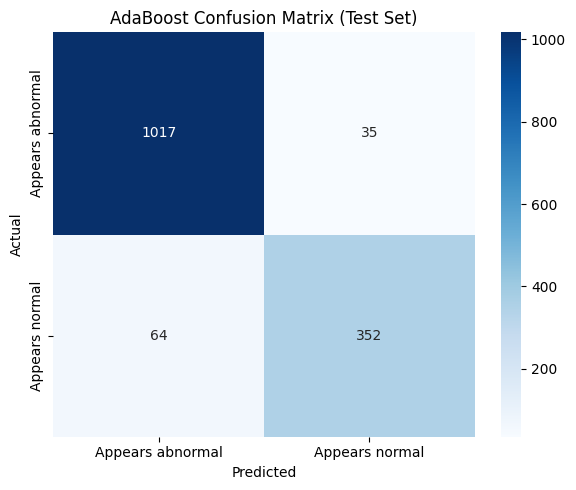


Final MobileNetV2 Test Loss: 0.4245 (CE: 0.3248, Dice: 0.5242), Final MobileNetV2 Test Accuracy: 0.9040

MobileNetV2 Test Precision (weighted): 0.9048
MobileNetV2 Test Recall (weighted): 0.9040
MobileNetV2 Test F1-score (weighted): 0.9004

MobileNetV2 Per-class report:
                  precision    recall  f1-score   support

Appears abnormal     0.9006    0.9734    0.9356      1052
  Appears normal     0.9154    0.7284    0.8112       416

        accuracy                         0.9040      1468
       macro avg     0.9080    0.8509    0.8734      1468
    weighted avg     0.9048    0.9040    0.9004      1468



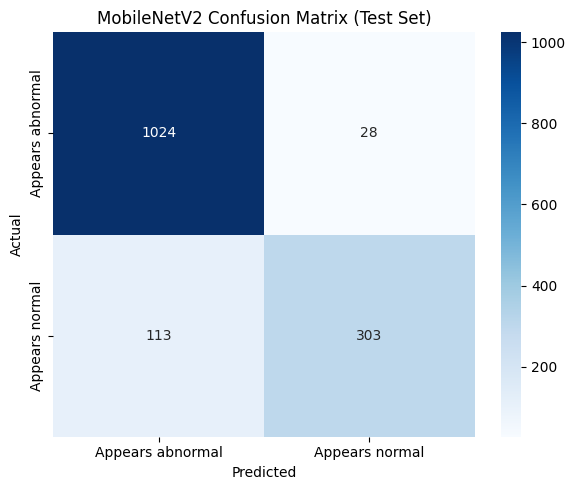

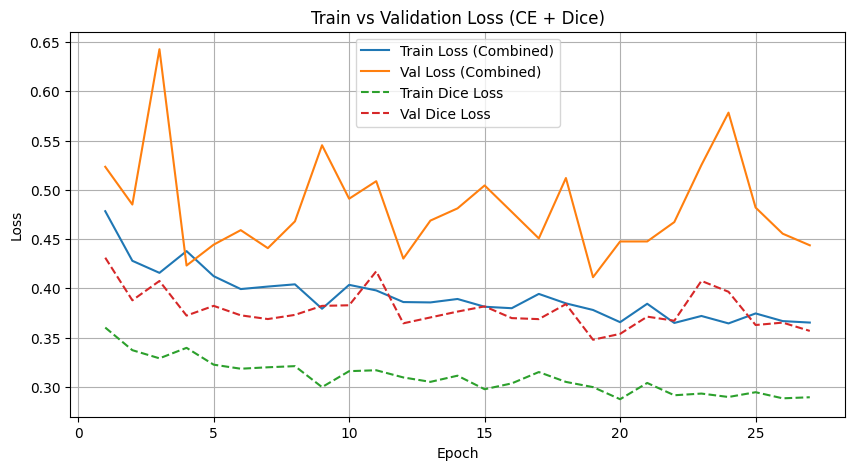

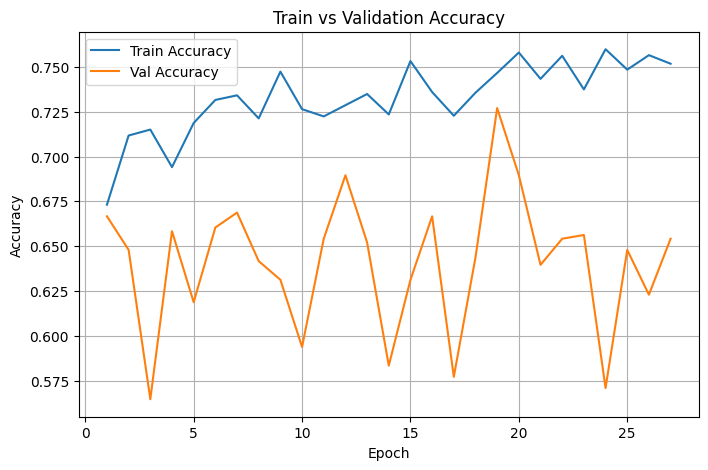


================ FINAL SUMMARY ================
Best MobileNetV2 Val Accuracy: 0.7271
MobileNetV2 Test Accuracy: 0.9040
MobileNetV2 Test Precision: 0.9048
MobileNetV2 Test Recall: 0.9040
MobileNetV2 Test F1-score: 0.9004
MobileNetV2 Test Dice Loss: 0.5242

---------------- AdaBoost ----------------
AdaBoost Validation Accuracy: 0.6521
AdaBoost Test Accuracy: 0.9326
AdaBoost Test Precision: 0.9319
AdaBoost Test Recall: 0.9326
AdaBoost Test F1-score: 0.9318


In [5]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, WeightedRandomSampler, random_split
from torchvision import datasets, transforms, models
from tqdm import tqdm
import numpy as np
import os
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from sklearn.ensemble import AdaBoostClassifier

import seaborn as sns


# ============================================================
# Device configuration
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


# ============================================================
# Paths to train and test datasets
# ============================================================

train_dir = '/kaggle/working/PCOSGen-train/train'
test_dir = '/kaggle/working/PCOSGen-train/test'


# ============================================================
# Image transformations
# ============================================================

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# ============================================================
# Datasets
# ============================================================

train_dataset = datasets.ImageFolder(
    train_dir,
    transform=train_transform
)

test_dataset = datasets.ImageFolder(
    test_dir,
    transform=test_transform
)


# ============================================================
# Split train_dataset into train_subset + val_subset (85/15)
# ============================================================

val_size = int(0.15 * len(train_dataset))

train_size = len(train_dataset) - val_size

train_subset, val_subset = random_split(
    train_dataset,
    [train_size, val_size]
)


# ============================================================
# Count samples per class within train_subset
# ============================================================

train_targets = [
    train_dataset.targets[i]
    for i in train_subset.indices
]

class_counts = np.bincount(
    train_targets
)

class_weights = 1. / class_counts

sample_weights = [
    class_weights[label]
    for label in train_targets
]


# ============================================================
# Weighted Random Sampler
# ============================================================

sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(train_subset),
    replacement=True
)


# ============================================================
# DataLoaders
# ============================================================

train_loader = DataLoader(
    train_subset,
    batch_size=64,
    sampler=sampler
)

val_loader = DataLoader(
    val_subset,
    batch_size=64,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)


# ============================================================
# Load pre-trained MobileNetV2
# ============================================================

mobilenet = models.mobilenet_v2(
    pretrained=True
)

num_classes = len(
    train_dataset.classes
)

mobilenet.classifier[1] = nn.Linear(
    mobilenet.classifier[1].in_features,
    num_classes
)

mobilenet = mobilenet.to(device)


# ============================================================
# Dice Loss
# ============================================================

class DiceLoss(nn.Module):

    def __init__(
        self,
        num_classes,
        smooth=1e-6
    ):

        super().__init__()

        self.num_classes = num_classes
        self.smooth = smooth


    def forward(
        self,
        logits,
        targets
    ):

        probs = F.softmax(
            logits,
            dim=1
        )

        targets_one_hot = F.one_hot(
            targets,
            num_classes=self.num_classes
        ).float()

        intersection = (
            probs * targets_one_hot
        ).sum(dim=0)

        union = (
            probs.sum(dim=0)
            +
            targets_one_hot.sum(dim=0)
        )

        dice_score = (
            2. * intersection
            +
            self.smooth
        ) / (
            union
            +
            self.smooth
        )

        dice_loss = (
            1.
            -
            dice_score.mean()
        )

        return dice_loss


# ============================================================
# Combined CrossEntropy + Dice Loss
# ============================================================

class CombinedLoss(nn.Module):

    def __init__(
        self,
        num_classes,
        ce_weight=0.5,
        dice_weight=0.5
    ):

        super().__init__()

        self.ce_loss = nn.CrossEntropyLoss()

        self.dice_loss = DiceLoss(
            num_classes
        )

        self.ce_weight = ce_weight
        self.dice_weight = dice_weight


    def forward(
        self,
        logits,
        targets
    ):

        ce = self.ce_loss(
            logits,
            targets
        )

        dice = self.dice_loss(
            logits,
            targets
        )

        total = (
            self.ce_weight * ce
            +
            self.dice_weight * dice
        )

        return total, ce, dice


criterion = CombinedLoss(
    num_classes=num_classes,
    ce_weight=0.5,
    dice_weight=0.5
)


# ============================================================
# Optimizer
# ============================================================

optimizer = optim.Adam(
    mobilenet.parameters(),
    lr=0.001
)


# ============================================================
# Function to evaluate MobileNetV2
# ============================================================

def evaluate_model(
    model,
    loader
):

    model.eval()

    correct = 0
    total = 0

    running_loss = 0.0
    running_ce = 0.0
    running_dice = 0.0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss, ce, dice = criterion(
                outputs,
                labels
            )

            running_loss += loss.item()
            running_ce += ce.item()
            running_dice += dice.item()

            _, predicted = torch.max(
                outputs,
                1
            )

            total += labels.size(0)

            correct += (
                predicted == labels
            ).sum().item()

    accuracy = correct / total

    n = len(loader)

    return (
        accuracy,
        running_loss / n,
        running_ce / n,
        running_dice / n
    )


# ============================================================
# Get predictions
# ============================================================

def get_predictions(
    model,
    loader
):

    model.eval()

    all_preds = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            _, predicted = torch.max(
                outputs,
                1
            )

            all_preds.extend(
                predicted.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    return all_labels, all_preds


# ============================================================
# Early stopping setup
# ============================================================

best_accuracy = 0.0

best_model_path = "Mobilenet_1410=.pkl"

patience = 8

epochs_no_improve = 0

max_epochs = 50


# ============================================================
# Lists for graphs
# ============================================================

train_losses = []
train_accs = []

val_losses = []
val_accs = []

train_ce_losses = []
train_dice_losses = []

val_ce_losses = []
val_dice_losses = []


# ============================================================
# MobileNetV2 Training
# ============================================================

for epoch in range(max_epochs):

    mobilenet.train()

    running_loss = 0.0
    running_ce = 0.0
    running_dice = 0.0

    correct_train = 0
    total_train = 0


    for images, labels in tqdm(
        train_loader
    ):

        images = images.to(device)
        labels = labels.to(device)

        outputs = mobilenet(
            images
        )

        loss, ce, dice = criterion(
            outputs,
            labels
        )

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        running_loss += loss.item()
        running_ce += ce.item()
        running_dice += dice.item()

        _, predicted = torch.max(
            outputs,
            1
        )

        total_train += labels.size(0)

        correct_train += (
            predicted == labels
        ).sum().item()


    train_accuracy = (
        correct_train /
        total_train
    )

    n_batches = len(
        train_loader
    )

    train_loss = (
        running_loss /
        n_batches
    )

    train_ce = (
        running_ce /
        n_batches
    )

    train_dice = (
        running_dice /
        n_batches
    )


    # ========================================================
    # Validation
    # ========================================================

    val_accuracy, val_loss, val_ce, val_dice = evaluate_model(
        mobilenet,
        val_loader
    )


    # ========================================================
    # Store values for graphs
    # ========================================================

    train_losses.append(
        train_loss
    )

    train_accs.append(
        train_accuracy
    )

    val_losses.append(
        val_loss
    )

    val_accs.append(
        val_accuracy
    )

    train_ce_losses.append(
        train_ce
    )

    train_dice_losses.append(
        train_dice
    )

    val_ce_losses.append(
        val_ce
    )

    val_dice_losses.append(
        val_dice
    )


    # ========================================================
    # Print epoch results
    # ========================================================

    print(
        f'Epoch [{epoch+1}/{max_epochs}] '
        f'Train Loss: {train_loss:.4f} '
        f'(CE: {train_ce:.4f}, '
        f'Dice: {train_dice:.4f}), '
        f'Train Acc: {train_accuracy:.4f} | '
        f'Val Loss: {val_loss:.4f} '
        f'(CE: {val_ce:.4f}, '
        f'Dice: {val_dice:.4f}), '
        f'Val Acc: {val_accuracy:.4f}'
    )


    # ========================================================
    # Early stopping logic
    # ========================================================

    if val_accuracy > best_accuracy:

        best_accuracy = val_accuracy

        epochs_no_improve = 0

        print(
            f'  -> Saving best model '
            f'(Val Accuracy: '
            f'{best_accuracy:.4f})'
        )

        torch.save(
            mobilenet.state_dict(),
            best_model_path
        )

    else:

        epochs_no_improve += 1

        print(
            f'  -> No improvement for '
            f'{epochs_no_improve}/{patience} epochs'
        )


    if epochs_no_improve >= patience:

        print(
            f'\nEarly stopping triggered at '
            f'epoch {epoch+1}. '
            f'Best Val Accuracy: '
            f'{best_accuracy:.4f}'
        )

        break


# ============================================================
# Load the best MobileNetV2 model
# ============================================================

best_mobilenet_model = models.mobilenet_v2(
    pretrained=False
)

best_mobilenet_model.classifier[1] = nn.Linear(
    mobilenet.classifier[1].in_features,
    num_classes
)

best_mobilenet_model = best_mobilenet_model.to(
    device
)

best_mobilenet_model.load_state_dict(
    torch.load(
        best_model_path
    )
)


# ============================================================
# ADABOOST
# MobileNetV2 Feature Extraction + AdaBoost
# ============================================================

def extract_features(
    model,
    loader
):

    model.eval()

    features = []
    labels_list = []

    with torch.no_grad():

        for images, labels in tqdm(
            loader,
            desc="Extracting Features"
        ):

            images = images.to(device)

            # Extract features before classifier
            x = model.features(
                images
            )

            # Global Average Pooling
            x = F.adaptive_avg_pool2d(
                x,
                (1, 1)
            )

            # Flatten
            x = torch.flatten(
                x,
                1
            )

            features.extend(
                x.cpu().numpy()
            )

            labels_list.extend(
                labels.numpy()
            )

    return (
        np.array(features),
        np.array(labels_list)
    )


print(
    "\nExtracting MobileNetV2 features..."
)


# ============================================================
# Feature Extraction
# ============================================================

train_features, train_labels = extract_features(
    best_mobilenet_model,
    train_loader
)

val_features, val_labels = extract_features(
    best_mobilenet_model,
    val_loader
)

test_features, test_labels = extract_features(
    best_mobilenet_model,
    test_loader
)


print(
    "\nFeature shape:",
    train_features.shape
)


# ============================================================
# Train AdaBoost
# ============================================================

adaboost_model = AdaBoostClassifier(
    n_estimators=100,
    learning_rate=1.0,
    random_state=42
)

print(
    "\nTraining AdaBoost..."
)

adaboost_model.fit(
    train_features,
    train_labels
)


# ============================================================
# AdaBoost Validation
# ============================================================

adaboost_val_preds = adaboost_model.predict(
    val_features
)

adaboost_val_accuracy = np.mean(
    adaboost_val_preds == val_labels
)

print(
    f"\nAdaBoost Validation Accuracy: "
    f"{adaboost_val_accuracy:.4f}"
)


# ============================================================
# AdaBoost Test Predictions
# ============================================================

adaboost_test_preds = adaboost_model.predict(
    test_features
)

adaboost_test_accuracy = np.mean(
    adaboost_test_preds == test_labels
)

print(
    f"AdaBoost Test Accuracy: "
    f"{adaboost_test_accuracy:.4f}"
)


# ============================================================
# AdaBoost Metrics
# ============================================================

class_names = train_dataset.classes


# Accuracy
adaboost_accuracy = np.mean(
    adaboost_test_preds == test_labels
)


# Weighted Precision
adaboost_precision = precision_score(
    test_labels,
    adaboost_test_preds,
    average='weighted',
    zero_division=0
)


# Weighted Recall
adaboost_recall = recall_score(
    test_labels,
    adaboost_test_preds,
    average='weighted',
    zero_division=0
)


# Weighted F1
adaboost_f1 = f1_score(
    test_labels,
    adaboost_test_preds,
    average='weighted',
    zero_division=0
)


print(
    "\n---------------- AdaBoost Metrics ----------------"
)

print(
    f"AdaBoost Test Accuracy: "
    f"{adaboost_accuracy:.4f}"
)

print(
    f"AdaBoost Test Precision (weighted): "
    f"{adaboost_precision:.4f}"
)

print(
    f"AdaBoost Test Recall (weighted): "
    f"{adaboost_recall:.4f}"
)

print(
    f"AdaBoost Test F1-score (weighted): "
    f"{adaboost_f1:.4f}"
)


# ============================================================
# AdaBoost Classification Report
# ============================================================

print(
    "\nAdaBoost Per-class report:"
)

print(
    classification_report(
        test_labels,
        adaboost_test_preds,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)


# ============================================================
# AdaBoost Confusion Matrix
# ============================================================

adaboost_cm = confusion_matrix(
    test_labels,
    adaboost_test_preds
)

plt.figure(
    figsize=(6, 5)
)

sns.heatmap(
    adaboost_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel(
    'Predicted'
)

plt.ylabel(
    'Actual'
)

plt.title(
    'AdaBoost Confusion Matrix (Test Set)'
)

plt.tight_layout()

plt.show()


# ============================================================
# ORIGINAL MOBILENETV2 TEST EVALUATION
# ============================================================
# Kept from your original version
# ============================================================

test_accuracy, test_loss, test_ce, test_dice = evaluate_model(
    best_mobilenet_model,
    test_loader
)

print(
    f'\nFinal MobileNetV2 Test Loss: '
    f'{test_loss:.4f} '
    f'(CE: {test_ce:.4f}, '
    f'Dice: {test_dice:.4f}), '
    f'Final MobileNetV2 Test Accuracy: '
    f'{test_accuracy:.4f}'
)


# ============================================================
# MobileNetV2 Test Metrics
# ============================================================

true_labels, pred_labels = get_predictions(
    best_mobilenet_model,
    test_loader
)


precision = precision_score(
    true_labels,
    pred_labels,
    average='weighted',
    zero_division=0
)

recall = recall_score(
    true_labels,
    pred_labels,
    average='weighted',
    zero_division=0
)

f1 = f1_score(
    true_labels,
    pred_labels,
    average='weighted',
    zero_division=0
)


print(
    f'\nMobileNetV2 Test Precision (weighted): '
    f'{precision:.4f}'
)

print(
    f'MobileNetV2 Test Recall (weighted): '
    f'{recall:.4f}'
)

print(
    f'MobileNetV2 Test F1-score (weighted): '
    f'{f1:.4f}'
)


# ============================================================
# MobileNetV2 Classification Report
# ============================================================

print(
    '\nMobileNetV2 Per-class report:'
)

print(
    classification_report(
        true_labels,
        pred_labels,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)


# ============================================================
# MobileNetV2 Confusion Matrix
# ============================================================

cm = confusion_matrix(
    true_labels,
    pred_labels
)

plt.figure(
    figsize=(6, 5)
)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel(
    'Predicted'
)

plt.ylabel(
    'Actual'
)

plt.title(
    'MobileNetV2 Confusion Matrix (Test Set)'
)

plt.tight_layout()

plt.show()


# ============================================================
# Plot Train vs Val Loss
# ============================================================

epochs_range = range(
    1,
    len(train_losses) + 1
)

plt.figure(
    figsize=(10, 5)
)

plt.plot(
    epochs_range,
    train_losses,
    label='Train Loss (Combined)'
)

plt.plot(
    epochs_range,
    val_losses,
    label='Val Loss (Combined)'
)

plt.plot(
    epochs_range,
    train_dice_losses,
    '--',
    label='Train Dice Loss'
)

plt.plot(
    epochs_range,
    val_dice_losses,
    '--',
    label='Val Dice Loss'
)

plt.xlabel(
    'Epoch'
)

plt.ylabel(
    'Loss'
)

plt.title(
    'Train vs Validation Loss (CE + Dice)'
)

plt.legend()

plt.grid(True)

plt.show()


# ============================================================
# Plot Train vs Val Accuracy
# ============================================================

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    epochs_range,
    train_accs,
    label='Train Accuracy'
)

plt.plot(
    epochs_range,
    val_accs,
    label='Val Accuracy'
)

plt.xlabel(
    'Epoch'
)

plt.ylabel(
    'Accuracy'
)

plt.title(
    'Train vs Validation Accuracy'
)

plt.legend()

plt.grid(True)

plt.show()


# ============================================================
# FINAL SUMMARY
# ============================================================

print(
    '\n================ FINAL SUMMARY ================'
)

print(
    f'Best MobileNetV2 Val Accuracy: '
    f'{best_accuracy:.4f}'
)

print(
    f'MobileNetV2 Test Accuracy: '
    f'{test_accuracy:.4f}'
)

print(
    f'MobileNetV2 Test Precision: '
    f'{precision:.4f}'
)

print(
    f'MobileNetV2 Test Recall: '
    f'{recall:.4f}'
)

print(
    f'MobileNetV2 Test F1-score: '
    f'{f1:.4f}'
)

print(
    f'MobileNetV2 Test Dice Loss: '
    f'{test_dice:.4f}'
)


print(
    '\n---------------- AdaBoost ----------------'
)

print(
    f'AdaBoost Validation Accuracy: '
    f'{adaboost_val_accuracy:.4f}'
)

print(
    f'AdaBoost Test Accuracy: '
    f'{adaboost_accuracy:.4f}'
)

print(
    f'AdaBoost Test Precision: '
    f'{adaboost_precision:.4f}'
)

print(
    f'AdaBoost Test Recall: '
    f'{adaboost_recall:.4f}'
)

print(
    f'AdaBoost Test F1-score: '
    f'{adaboost_f1:.4f}'
)